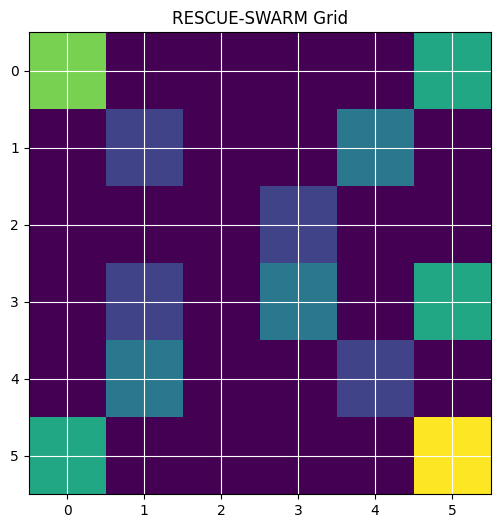

Training independent agents...
Training cooperative agents...

=== INDEPENDENT Q-LEARNING ===
rescues: 3.00
steps: 5.00
reward: 35.00
collisions: 0.00

=== COOPERATIVE Q-LEARNING ===
rescues: 3.00
steps: 6.00
reward: 33.00
collisions: 0.00

=== TRAINING COMPARISON ===
Independent average reward: -22.04
Cooperative average reward: 6.42
Independent average rescues: 2.82
Cooperative average rescues: 2.82


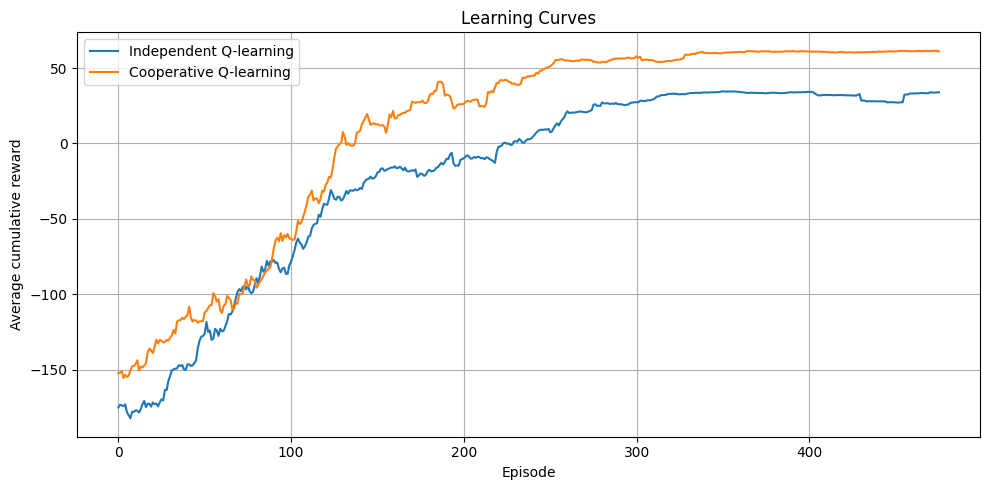

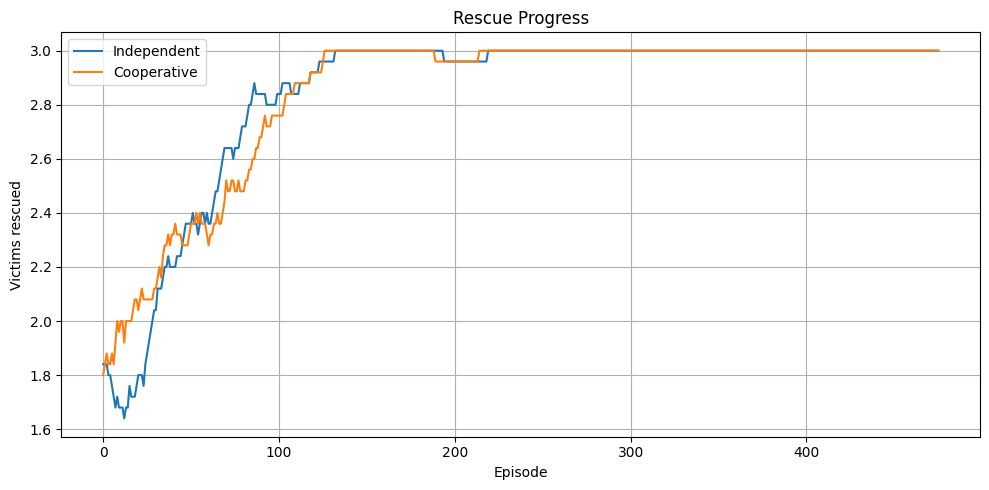

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

GRID_SIZE = 6
N_AGENTS = 2
EPISODES = 500
MAX_STEPS = 60

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1), (0, 0)]

OBSTACLES = {(1, 1), (2, 3), (3, 1), (4, 4)}
HAZARDS = {(1, 4), (3, 3), (4, 1)}
STARTS = [(0, 0), (5, 5)]
VICTIMS = [(0, 5), (3, 5), (5, 0)]


def move(pos, action):
    dr, dc = ACTIONS[action]
    new_pos = (pos[0] + dr, pos[1] + dc)

    if not (0 <= new_pos[0] < GRID_SIZE and
            0 <= new_pos[1] < GRID_SIZE):
        return pos

    if new_pos in OBSTACLES:
        return pos

    return new_pos


def get_state(pos, victims):
    return pos, tuple(sorted(victims))


def choose_action(q, state, epsilon):
    if np.random.random() < epsilon:
        return np.random.randint(len(ACTIONS))

    values = q[state]
    best = np.flatnonzero(values == values.max())
    return int(np.random.choice(best))


def train(cooperative, episodes=EPISODES):
    q_tables = [
        defaultdict(lambda: np.zeros(len(ACTIONS)))
        for _ in range(N_AGENTS)
    ]

    rewards_history = []
    rescues_history = []
    steps_history = []
    collisions_history = []

    for episode in range(episodes):
        positions = list(STARTS)
        victims = set(VICTIMS)

        total_reward = 0
        rescues = 0
        collisions = 0
        steps_used = 0

        epsilon = max(0.05, 1 - episode / (episodes * 0.75))

        for step in range(MAX_STEPS):
            steps_used = step + 1
            old_positions = list(positions)
            old_victims = set(victims)

            actions = []

            for i in range(N_AGENTS):
                state = get_state(positions[i], victims)
                actions.append(
                    choose_action(q_tables[i], state, epsilon)
                )

            proposed = [
                move(positions[i], actions[i])
                for i in range(N_AGENTS)
            ]

            collision_agents = set()

            if proposed[0] == proposed[1]:
                collisions += 1
                collision_agents = {0, 1}
                proposed = old_positions[:]

            rewards = [-1.0, -1.0]

            for i in range(N_AGENTS):
                if proposed[i] == old_positions[i] and actions[i] != 4:
                    rewards[i] -= 1

                if proposed[i] in HAZARDS:
                    rewards[i] -= 5

                if i in collision_agents:
                    rewards[i] -= 4

            positions = proposed

            rescued_now = set()

            for i, pos in enumerate(positions):
                if pos in victims:
                    rescued_now.add(pos)
                    rewards[i] += 15

            victims -= rescued_now
            rescues += len(rescued_now)

            if cooperative:
                shared_reward = sum(rewards) / N_AGENTS

                rewards = [shared_reward, shared_reward]

                if rescued_now:
                    bonus = 5 * len(rescued_now)
                    rewards = [r + bonus for r in rewards]

            total_reward += sum(rewards)

            for i in range(N_AGENTS):
                old_state = get_state(old_positions[i], old_victims)
                new_state = get_state(positions[i], victims)

                action = actions[i]
                alpha = 0.15
                gamma = 0.90

                target = rewards[i]

                if victims:
                    target += gamma * np.max(q_tables[i][new_state])

                q_tables[i][old_state][action] += alpha * (
                    target - q_tables[i][old_state][action]
                )

            if not victims:
                break

        rewards_history.append(total_reward)
        rescues_history.append(rescues)
        steps_history.append(steps_used)
        collisions_history.append(collisions)

    return {
        "q_tables": q_tables,
        "rewards": rewards_history,
        "rescues": rescues_history,
        "steps": steps_history,
        "collisions": collisions_history
    }


def evaluate(model, trials=100):
    q_tables = model["q_tables"]
    results = []

    for _ in range(trials):
        positions = list(STARTS)
        victims = set(VICTIMS)

        total_reward = 0
        rescues = 0
        collisions = 0
        steps_used = 0

        for step in range(MAX_STEPS):
            steps_used = step + 1
            old_positions = list(positions)
            proposed = []

            for i in range(N_AGENTS):
                state = get_state(positions[i], victims)
                action = int(np.argmax(q_tables[i][state]))
                proposed.append(move(positions[i], action))

            if proposed[0] == proposed[1]:
                collisions += 1
                proposed = old_positions[:]

            positions = proposed

            for pos in positions:
                total_reward -= 1

                if pos in HAZARDS:
                    total_reward -= 5

            rescued_now = victims.intersection(positions)
            rescues += len(rescued_now)
            victims -= rescued_now
            total_reward += 15 * len(rescued_now)

            if not victims:
                break

        results.append({
            "rescues": rescues,
            "steps": steps_used,
            "reward": total_reward,
            "collisions": collisions
        })

    return {
        key: np.mean([trial[key] for trial in results])
        for key in results[0]
    }


def show_grid():
    grid = np.zeros((GRID_SIZE, GRID_SIZE))

    for pos in OBSTACLES:
        grid[pos] = 1

    for pos in HAZARDS:
        grid[pos] = 2

    for pos in VICTIMS:
        grid[pos] = 3

    for i, pos in enumerate(STARTS):
        grid[pos] = 4 + i

    plt.figure(figsize=(6, 6))
    plt.imshow(grid, cmap="viridis", vmin=0, vmax=5)
    plt.xticks(range(GRID_SIZE))
    plt.yticks(range(GRID_SIZE))
    plt.grid(True, color="white")
    plt.title("RESCUE-SWARM Grid")
    plt.show()


def plot_learning(independent, cooperative):
    def smooth(values, window=25):
        values = np.asarray(values, dtype=float)

        if len(values) < window:
            return values

        return np.convolve(
            values, np.ones(window) / window, mode="valid"
        )

    plt.figure(figsize=(10, 5))
    plt.plot(
        smooth(independent["rewards"]),
        label="Independent Q-learning"
    )
    plt.plot(
        smooth(cooperative["rewards"]),
        label="Cooperative Q-learning"
    )
    plt.xlabel("Episode")
    plt.ylabel("Average cumulative reward")
    plt.title("Learning Curves")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(
        smooth(independent["rescues"]),
        label="Independent"
    )
    plt.plot(
        smooth(cooperative["rescues"]),
        label="Cooperative"
    )
    plt.xlabel("Episode")
    plt.ylabel("Victims rescued")
    plt.title("Rescue Progress")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


def main():
    np.random.seed(42)

    show_grid()

    print("Training independent agents...")
    independent = train(cooperative=False)

    print("Training cooperative agents...")
    cooperative = train(cooperative=True)

    ind_result = evaluate(independent)
    coop_result = evaluate(cooperative)

    print("\n=== INDEPENDENT Q-LEARNING ===")

    for key, value in ind_result.items():
        print(f"{key}: {value:.2f}")

    print("\n=== COOPERATIVE Q-LEARNING ===")

    for key, value in coop_result.items():
        print(f"{key}: {value:.2f}")

    print("\n=== TRAINING COMPARISON ===")
    print("Independent average reward:",
          round(np.mean(independent["rewards"]), 2))
    print("Cooperative average reward:",
          round(np.mean(cooperative["rewards"]), 2))

    print("Independent average rescues:",
          round(np.mean(independent["rescues"]), 2))
    print("Cooperative average rescues:",
          round(np.mean(cooperative["rescues"]), 2))

    plot_learning(independent, cooperative)


if __name__ == "__main__":
    main()